# Assignment 7 - Transformers Basics

**Name:** Liya Tekie  
**Class:** DATA 575  
**Assignment:** Annotated Transformer Part 1 and Part 2

This notebook reproduces Part 1 and Part 2 of the Harvard Annotated Transformer.
The code follows the Transformer architecture from the "Attention Is All You Need" paper.

# Part 1: Model Architecture

In [61]:
import copy
import math
import time

import numpy as np
import pandas as pd
import altair as alt
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.nn.functional import log_softmax, pad

In [62]:
class EncoderDecoder(nn.Module):
    """
    A standard Encoder-Decoder architecture.
    """

    def __init__(self, encoder, decoder, src_embed, tgt_embed, generator):
        super(EncoderDecoder, self).__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.src_embed = src_embed
        self.tgt_embed = tgt_embed
        self.generator = generator

    def forward(self, src, tgt, src_mask, tgt_mask):
        return self.decode(
            self.encode(src, src_mask), src_mask, tgt, tgt_mask
        )

    def encode(self, src, src_mask):
        return self.encoder(self.src_embed(src), src_mask)

    def decode(self, memory, src_mask, tgt, tgt_mask):
        return self.decoder(
            self.tgt_embed(tgt), memory, src_mask, tgt_mask
        )

In [63]:
class Generator(nn.Module):
    """
    Define standard linear + softmax generation step.
    """

    def __init__(self, d_model, vocab):
        super(Generator, self).__init__()
        self.proj = nn.Linear(d_model, vocab)

    def forward(self, x):
        return log_softmax(self.proj(x), dim=-1)

In [64]:
def clones(module, N):
    """
    Produce N identical layers.
    """
    return nn.ModuleList([copy.deepcopy(module) for _ in range(N)])

In [65]:
class Encoder(nn.Module):
    """
    Core encoder is a stack of N layers.
    """

    def __init__(self, layer, N):
        super(Encoder, self).__init__()
        self.layers = clones(layer, N)
        self.norm = LayerNorm(layer.size)

    def forward(self, x, mask):
        """
        Pass the input and mask through each layer.
        """
        for layer in self.layers:
            x = layer(x, mask)
        return self.norm(x)

In [66]:
class LayerNorm(nn.Module):
    """
    Construct a layer normalization module.
    """

    def __init__(self, features, eps=1e-6):
        super(LayerNorm, self).__init__()
        self.a_2 = nn.Parameter(torch.ones(features))
        self.b_2 = nn.Parameter(torch.zeros(features))
        self.eps = eps

    def forward(self, x):
        mean = x.mean(-1, keepdim=True)
        std = x.std(-1, keepdim=True)
        return self.a_2 * (x - mean) / (std + self.eps) + self.b_2

In [67]:
class SublayerConnection(nn.Module):
    """
    A residual connection followed by layer normalization.
    """

    def __init__(self, size, dropout):
        super(SublayerConnection, self).__init__()
        self.norm = LayerNorm(size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, sublayer):
        return x + self.dropout(sublayer(self.norm(x)))

In [68]:
class EncoderLayer(nn.Module):
    """
    Encoder is made up of self-attention and feed forward.
    """

    def __init__(self, size, self_attn, feed_forward, dropout):
        super(EncoderLayer, self).__init__()
        self.self_attn = self_attn
        self.feed_forward = feed_forward
        self.sublayer = clones(SublayerConnection(size, dropout), 2)
        self.size = size

    def forward(self, x, mask):
        x = self.sublayer[0](x, lambda x: self.self_attn(x, x, x, mask))
        return self.sublayer[1](x, self.feed_forward)

In [69]:
class Decoder(nn.Module):
    """
    Generic N layer decoder with masking.
    """

    def __init__(self, layer, N):
        super(Decoder, self).__init__()
        self.layers = clones(layer, N)
        self.norm = LayerNorm(layer.size)

    def forward(self, x, memory, src_mask, tgt_mask):
        for layer in self.layers:
            x = layer(x, memory, src_mask, tgt_mask)
        return self.norm(x)

In [70]:
class DecoderLayer(nn.Module):
    """
    Decoder is made of self-attention, source-attention,
    and feed-forward.
    """

    def __init__(self, size, self_attn, src_attn, feed_forward, dropout):
        super(DecoderLayer, self).__init__()
        self.size = size
        self.self_attn = self_attn
        self.src_attn = src_attn
        self.feed_forward = feed_forward
        self.sublayer = clones(SublayerConnection(size, dropout), 3)

    def forward(self, x, memory, src_mask, tgt_mask):
        m = memory

        x = self.sublayer[0](
            x, lambda x: self.self_attn(x, x, x, tgt_mask)
        )

        x = self.sublayer[1](
            x, lambda x: self.src_attn(x, m, m, src_mask)
        )

        return self.sublayer[2](x, self.feed_forward)

In [71]:
def subsequent_mask(size):
    """
    Mask out future positions.
    """
    attn_shape = (1, size, size)
    subsequent_mask = torch.triu(
        torch.ones(attn_shape), diagonal=1
    ).type(torch.uint8)

    return subsequent_mask == 0

In [72]:
def attention(query, key, value, mask=None, dropout=None):
    """
    Compute Scaled Dot Product Attention.
    """
    d_k = query.size(-1)

    scores = torch.matmul(
        query, key.transpose(-2, -1)
    ) / math.sqrt(d_k)

    if mask is not None:
        scores = scores.masked_fill(mask == 0, -1e9)

    p_attn = scores.softmax(dim=-1)

    if dropout is not None:
        p_attn = dropout(p_attn)

    return torch.matmul(p_attn, value), p_attn

In [73]:
class MultiHeadedAttention(nn.Module):
    """
    Multi-Head Attention.
    """

    def __init__(self, h, d_model, dropout=0.1):
        super(MultiHeadedAttention, self).__init__()

        assert d_model % h == 0

        self.d_k = d_model // h
        self.h = h
        self.linears = clones(nn.Linear(d_model, d_model), 4)
        self.attn = None
        self.dropout = nn.Dropout(p=dropout)

    def forward(self, query, key, value, mask=None):
        if mask is not None:
            mask = mask.unsqueeze(1)

        nbatches = query.size(0)

        query, key, value = [
            lin(x)
            .view(nbatches, -1, self.h, self.d_k)
            .transpose(1, 2)
            for lin, x in zip(self.linears, (query, key, value))
        ]

        x, self.attn = attention(
            query,
            key,
            value,
            mask=mask,
            dropout=self.dropout
        )

        x = (
            x.transpose(1, 2)
            .contiguous()
            .view(nbatches, -1, self.h * self.d_k)
        )

        return self.linears[-1](x)

In [74]:
class PositionwiseFeedForward(nn.Module):
    """
    Implements FFN equation.
    """

    def __init__(self, d_model, d_ff, dropout=0.1):
        super(PositionwiseFeedForward, self).__init__()
        self.w_1 = nn.Linear(d_model, d_ff)
        self.w_2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.w_2(
            self.dropout(self.w_1(x).relu())
        )

In [75]:
class Embeddings(nn.Module):
    """
    Convert token IDs into embedding vectors.
    """

    def __init__(self, d_model, vocab):
        super(Embeddings, self).__init__()
        self.lut = nn.Embedding(vocab, d_model)
        self.d_model = d_model

    def forward(self, x):
        return self.lut(x) * math.sqrt(self.d_model)

In [76]:
class PositionalEncoding(nn.Module):
    """
    Add positional information to the embeddings.
    """

    def __init__(self, d_model, dropout, max_len=5000):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(p=dropout)

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2) *
            -(math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        pe = pe.unsqueeze(0)
        self.register_buffer("pe", pe)

    def forward(self, x):
        x = x + self.pe[:, :x.size(1)].requires_grad_(False)
        return self.dropout(x)

In [77]:
def make_model(
    src_vocab,
    tgt_vocab,
    N=6,
    d_model=512,
    d_ff=2048,
    h=8,
    dropout=0.1,
):
    """
    Construct a complete Transformer model.
    """

    c = copy.deepcopy
    attn = MultiHeadedAttention(h, d_model)
    ff = PositionwiseFeedForward(d_model, d_ff, dropout)
    position = PositionalEncoding(d_model, dropout)

    model = EncoderDecoder(
        Encoder(
            EncoderLayer(
                d_model,
                c(attn),
                c(ff),
                dropout
            ),
            N
        ),

        Decoder(
            DecoderLayer(
                d_model,
                c(attn),
                c(attn),
                c(ff),
                dropout
            ),
            N
        ),

        nn.Sequential(
            Embeddings(d_model, src_vocab),
            c(position)
        ),

        nn.Sequential(
            Embeddings(d_model, tgt_vocab),
            c(position)
        ),

        Generator(d_model, tgt_vocab)
    )

    # Initialize model parameters
    for p in model.parameters():
        if p.dim() > 1:
            nn.init.xavier_uniform_(p)

    return model

In [78]:
def inference_test():
    test_model = make_model(11, 11, 2)
    test_model.eval()

    src = torch.LongTensor(
        [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]
    )

    src_mask = torch.ones(1, 1, 10)

    memory = test_model.encode(src, src_mask)

    ys = torch.zeros(1, 1).type_as(src)

    for i in range(9):
        out = test_model.decode(
            memory,
            src_mask,
            ys,
            subsequent_mask(ys.size(1)).type_as(src.data),
        )

        prob = test_model.generator(out[:, -1])

        _, next_word = torch.max(prob, dim=1)
        next_word = next_word.data[0]

        ys = torch.cat(
            [
                ys,
                torch.empty(1, 1)
                .type_as(src.data)
                .fill_(next_word),
            ],
            dim=1,
        )

    print("Example Untrained Model Prediction:", ys)


def run_tests():
    for _ in range(10):
        inference_test()


run_tests()

Example Untrained Model Prediction: tensor([[ 0, 10,  3, 10,  3, 10,  3, 10,  3, 10]])
Example Untrained Model Prediction: tensor([[0, 4, 6, 6, 6, 6, 6, 6, 6, 6]])
Example Untrained Model Prediction: tensor([[0, 4, 5, 0, 4, 5, 4, 4, 4, 4]])
Example Untrained Model Prediction: tensor([[ 0,  2,  2,  7,  2,  9, 10,  7,  2,  2]])
Example Untrained Model Prediction: tensor([[0, 1, 6, 2, 6, 1, 6, 5, 1, 6]])
Example Untrained Model Prediction: tensor([[ 0,  7,  9,  5,  0,  7,  7, 10,  5,  0]])
Example Untrained Model Prediction: tensor([[0, 2, 3, 6, 6, 1, 1, 1, 1, 1]])
Example Untrained Model Prediction: tensor([[0, 9, 9, 9, 9, 9, 9, 9, 9, 9]])
Example Untrained Model Prediction: tensor([[ 0,  6, 10,  9,  9,  9,  9,  9,  9,  9]])
Example Untrained Model Prediction: tensor([[0, 4, 2, 8, 6, 4, 2, 8, 1, 8]])


# Part 2: Model Training

This part focuses on training the Transformer model. It includes batching, masking, the training loop, optimization, and regularization.

## Batches and Masking

The Batch class prepares the source and target data for training. It also creates masks to ignore padding and prevent the decoder from seeing future tokens.

In [79]:
class Batch:
    """
    Object for holding a batch of data with mask during training.
    """

    def __init__(self, src, tgt=None, pad=2):
        self.src = src
        self.src_mask = (src != pad).unsqueeze(-2)

        if tgt is not None:
            self.tgt = tgt[:, :-1]
            self.tgt_y = tgt[:, 1:]
            self.tgt_mask = self.make_std_mask(self.tgt, pad)
            self.ntokens = (self.tgt_y != pad).data.sum()

    @staticmethod
    def make_std_mask(tgt, pad):
        """
        Create a mask to hide padding and future words.
        """
        tgt_mask = (tgt != pad).unsqueeze(-2)
        tgt_mask = tgt_mask & subsequent_mask(
            tgt.size(-1)
        ).type_as(tgt_mask.data)

        return tgt_mask
        return tgt_mask

## Training Loop

This section keeps track of the training process and runs the model through each batch of data.

In [80]:
class TrainState:
    """
    Track the number of steps and examples during training.
    """

    step: int = 0
    accum_step: int = 0
    samples: int = 0
    tokens: int = 0

In [81]:
def run_epoch(
    data_iter,
    model,
    loss_compute,
    optimizer,
    scheduler,
    mode="train",
    accum_iter=1,
    train_state=TrainState(),
):
    """
    Train a single epoch.
    """
    start = time.time()
    total_tokens = 0
    total_loss = 0
    tokens = 0
    n_accum = 0

    for i, batch in enumerate(data_iter):
        out = model.forward(
            batch.src,
            batch.tgt,
            batch.src_mask,
            batch.tgt_mask
        )

        loss, loss_node = loss_compute(
            out,
            batch.tgt_y,
            batch.ntokens
        )

        if mode == "train" or mode == "train+log":
            loss_node.backward()

            train_state.step += 1
            train_state.samples += batch.src.shape[0]
            train_state.tokens += batch.ntokens

            if i % accum_iter == 0:
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)

                n_accum += 1
                train_state.accum_step += 1

            scheduler.step()

        total_loss += loss
        total_tokens += batch.ntokens
        tokens += batch.ntokens

        if i % 40 == 1 and (
            mode == "train" or mode == "train+log"
        ):
            lr = optimizer.param_groups[0]["lr"]
            elapsed = time.time() - start

            print(
                (
                    "Epoch Step: %6d | Accumulation Step: %3d | "
                    "Loss: %6.2f | Tokens / Sec: %7.1f | "
                    "Learning Rate: %6.1e"
                )
                % (
                    i,
                    n_accum,
                    loss / batch.ntokens,
                    tokens / elapsed,
                    lr,
                )
            )

            start = time.time()
            tokens = 0

    return total_loss / total_tokens, train_state

## Training Data and Batching

This section prepares the data in batches so the Transformer can process and train on the data efficiently.

In [82]:
def batch_size_fn(new, count, sofar):
    """
    Keep augmenting batch and calculate total number of tokens.
    """
    global max_src_in_batch, max_tgt_in_batch

    if count == 1:
        max_src_in_batch = 0
        max_tgt_in_batch = 0

    max_src_in_batch = max(
        max_src_in_batch,
        len(new.src)
    )

    max_tgt_in_batch = max(
        max_tgt_in_batch,
        len(new.trg) + 2
    )

    src_elements = count * max_src_in_batch
    tgt_elements = count * max_tgt_in_batch

    return max(src_elements, tgt_elements)

## Optimizer and Learning Rate

The Transformer uses the Adam optimizer and changes the learning rate during training. The warmup steps help the model start training more gradually.

In [83]:
def rate(step, model_size, factor, warmup):
    """
    Calculate the learning rate used during training.
    """
    if step == 0:
        step = 1

    return factor * (
        model_size ** (-0.5)
        * min(
            step ** (-0.5),
            step * warmup ** (-1.5)
        )
    )

## Regularization - Label Smoothing

Label smoothing helps prevent the model from becoming too confident in its predictions. It gives a small amount of probability to other possible tokens.

In [84]:
class LabelSmoothing(nn.Module):
    """
    Implement label smoothing.
    """

    def __init__(self, size, padding_idx, smoothing=0.0):
        super(LabelSmoothing, self).__init__()
        self.criterion = nn.KLDivLoss(reduction="sum")
        self.padding_idx = padding_idx
        self.confidence = 1.0 - smoothing
        self.smoothing = smoothing
        self.size = size
        self.true_dist = None

    def forward(self, x, target):
        assert x.size(1) == self.size

        true_dist = x.data.clone()
        true_dist.fill_(
            self.smoothing / (self.size - 2)
        )

        true_dist.scatter_(
            1,
            target.data.unsqueeze(1),
            self.confidence
        )

        true_dist[:, self.padding_idx] = 0

        mask = torch.nonzero(
            target.data == self.padding_idx
        )

        if mask.dim() > 0:
            true_dist.index_fill_(
                0,
                mask.squeeze(),
                0.0
            )

        self.true_dist = true_dist

        return self.criterion(
            x,
            true_dist.clone().detach()
        )

## Label Smoothing Visualization

This example shows how label smoothing distributes some probability to other possible tokens instead of making the model completely confident in one prediction.

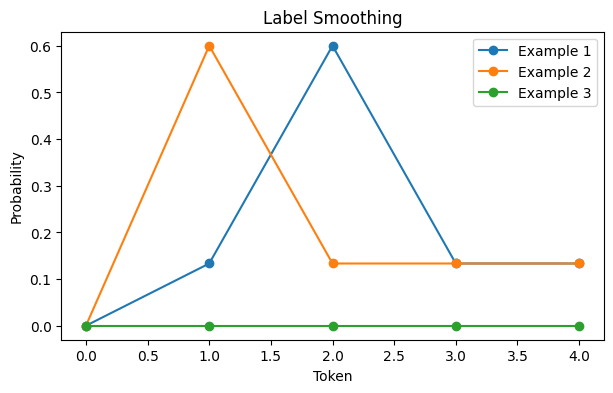

In [85]:
def example_label_smoothing():
    crit = LabelSmoothing(
        size=5,
        padding_idx=0,
        smoothing=0.4
    )

    predict = torch.FloatTensor(
        [
            [0, 0.2, 0.7, 0.1, 0],
            [0, 0.2, 0.7, 0.1, 0],
            [0, 0.2, 0.7, 0.1, 0],
        ]
    )

    crit(
        predict.log(),
        torch.LongTensor([2, 1, 0])
    )

    return crit.true_dist


true_dist = example_label_smoothing()

plt.figure(figsize=(7, 4))

for i in range(true_dist.shape[0]):
    plt.plot(
        range(true_dist.shape[1]),
        true_dist[i].numpy(),
        marker="o",
        label=f"Example {i + 1}"
    )

plt.xlabel("Token")
plt.ylabel("Probability")
plt.title("Label Smoothing")
plt.legend()
plt.show()